In [ ]:
import os
import json
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
from IPython.display import display

_env_file = find_dotenv()
REPO_DIR = Path(_env_file).parent.resolve()
load_dotenv(_env_file)

# Font amb suport complet Unicode (accents + simbols grecs)
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
matplotlib.rcParams['axes.unicode_minus'] = False

In [ ]:
# ── Selecciona l'experiment a analitzar ─────────────────────────────────────
# "" = últim experiment creat
# Juny 2026 (nous atributs sensibles):
#   "20260611_195149"  NIH + age_group      (sense config.json)
#   "20260612_015945"  NIH + age_group
#   "20260612_015952"  CheXpert + age_group
#   "20260616_224807"  NIH + view_pos_binary
#   "20260617_201322"  CheXpert + view_pos_binary
#   "20260618_125704"  CheXpert + age_group (B)
#   "20260618_192601"  CheXpert + view_pos_binary (B)
experiment = "20260612_015945"

In [ ]:
# ── Carrega config i resultats ───────────────────────────────────────────────
RESULTS_BASE = REPO_DIR / "results" / "sweep_bias_accuracy"

if experiment == "":
    candidates = sorted([d for d in RESULTS_BASE.iterdir() if d.is_dir()])
    if not candidates:
        raise FileNotFoundError(f"No hi ha experiments a {RESULTS_BASE}")
    EXP_DIR = candidates[-1]
    print(f"Carregant últim experiment: {EXP_DIR.name}")
else:
    EXP_DIR = RESULTS_BASE / experiment
    if not EXP_DIR.exists():
        available = [d.name for d in RESULTS_BASE.iterdir() if d.is_dir()]
        raise FileNotFoundError(f"Experiment '{experiment}' no trobat.\nDisponibles: {available}")

RESULTS_FILE = EXP_DIR / "sweep_results_v2.json"
if not RESULTS_FILE.exists():
    raise FileNotFoundError(f"Encara no hi ha resultats a {RESULTS_FILE}")

with open(RESULTS_FILE) as f:
    all_results = json.load(f)

# ── Config (pot no existir per experiments antics) ───────────────────────────
CONFIG_FILE = EXP_DIR / "config.json"
if CONFIG_FILE.exists():
    with open(CONFIG_FILE) as f:
        config = json.load(f)
else:
    # Infereix config dels resultats
    alphas  = sorted(set(r['alpha'] for r in all_results))
    lss     = sorted(set(r['ls'] for r in all_results))
    n_runs  = max(r['run_id'] for r in all_results) + 1
    config  = {
        'N_RUNS': n_runs, 'BASE_SEED': 42,
        'ALPHAS': alphas, 'LAYER_SIZES': lss,
        'MAX_EPOCHS': '?', 'PATIENCE': '?', 'BATCH_SIZE': '?',
        'FAIRNESS_LOSS': 'tpr_parity',
        'DATASET': '?',
        'SENSITIVE_ATTR': all_results[0].get('sensitive_attr', 'gender'),
        'GROUP_LABELS': None,
    }
    print("⚠ config.json no trobat — config inferida dels resultats.")

N_RUNS = config["N_RUNS"]

# ── Atribut sensible i grups ─────────────────────────────────────────────────
SENSITIVE_ATTR = config.get("SENSITIVE_ATTR", "gender")
GROUP_LABELS   = config.get("GROUP_LABELS")   # {str(int): str} | None per experiments de gènere antics

# Si GROUP_LABELS és None (experiment antic o sense config), infereix dels noms de columna
if GROUP_LABELS is None:
    tpr_group_cols = [k for k in all_results[0].keys() if k.startswith('tpr_') and k != 'tpr_gap']
    GROUP_LABELS   = {str(i): c.replace('tpr_', '').capitalize() for i, c in enumerate(tpr_group_cols)}

# Columnes TPR per grup i columna AUC sensible
tpr_cols          = [f"tpr_{label.lower()}" for label in GROUP_LABELS.values()]
sensitive_auc_col = "sensitive_auc_last_layer" if "sensitive_auc_last_layer" in all_results[0] else "gender_auc_last_layer"

# Etiqueta llegible de l'atribut sensible
_labels = {"gender": "Gènere", "age_group": "Edat", "view_pos_binary": "Posició radiografia"}
sensitive_label = _labels.get(SENSITIVE_ATTR, SENSITIVE_ATTR)

total_configs = len(config['ALPHAS']) * len(config['LAYER_SIZES']) * N_RUNS
print(f"Experiment   : {EXP_DIR.name}")
print(f"Dataset      : {config.get('DATASET')}")
print(f"Atribut sens.: {SENSITIVE_ATTR} ({sensitive_label})")
print(f"Grups        : {GROUP_LABELS}")
print(f"TPR cols     : {tpr_cols}")
print(f"AUC col      : {sensitive_auc_col}")
print(f"Config       : {config}")
print(f"Runs completats: {len(all_results)} / {total_configs}")

In [ ]:
# Taula: mitjana +/- std per configuracio
df_runs = pd.DataFrame(all_results)

METRICS = ['accuracy', 'auc_all'] + tpr_cols + ['tpr_gap', sensitive_auc_col]
METRICS = [m for m in METRICS if m in df_runs.columns]

agg = df_runs.groupby(['alpha', 'ls'])[METRICS].agg(['mean', 'std']).reset_index()
agg.columns = ['alpha', 'ls'] + [f'{m}_{s}' for m, s in agg.columns[2:]]
agg['n_runs'] = df_runs.groupby(['alpha', 'ls']).size().values
agg = agg.sort_values(['alpha', 'ls']).reset_index(drop=True)

display_df = agg[['alpha', 'ls', 'n_runs']].copy()
for m in METRICS:
    display_df[m] = agg[f'{m}_mean'].map('{:.3f}'.format) + ' +/- ' + agg[f'{m}_std'].map('{:.3f}'.format)

display(display_df.style
        .set_caption(f'Resultats sweep (mitjana +/- std, N={N_RUNS} runs per config)'))

# Paleta dinamica
unique_alphas = sorted(agg['alpha'].unique())
unique_ls     = sorted(agg['ls'].unique())

n = max(len(unique_alphas), 1)
_cmap = matplotlib.colormaps['tab20']
alpha_colors = {a: _cmap(i / n) for i, a in enumerate(unique_alphas)}

_markers   = ['o', 's', 'D', 'v', '^', 'p', 'P', '*', 'X', 'h', '<', '>']
ls_markers = {l: _markers[i % len(_markers)] for i, l in enumerate(unique_ls)}

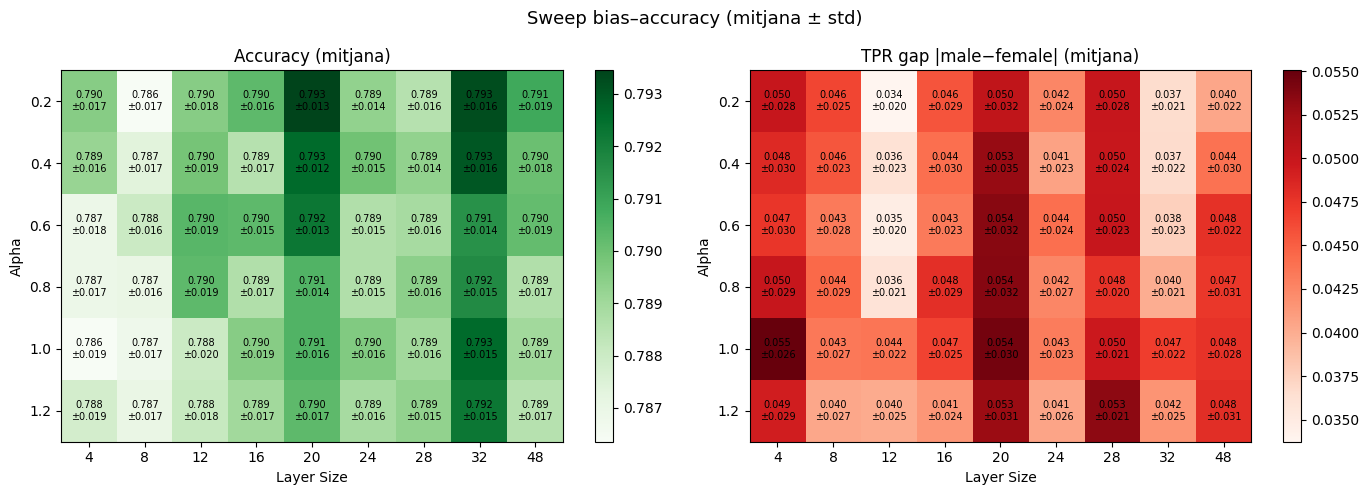

In [15]:
# ── Heatmaps: accuracy i tpr_gap ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, cmap, title in [
    (axes[0], 'accuracy', 'Greens', 'Accuracy (mitjana)'),
    (axes[1], 'tpr_gap',  'Reds',   'TPR gap |male−female| (mitjana)'),
]:
    pivot_mean = agg.pivot(index='alpha', columns='ls', values=f'{metric}_mean')
    pivot_std  = agg.pivot(index='alpha', columns='ls', values=f'{metric}_std')

    im = ax.imshow(pivot_mean.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(pivot_mean.columns)))
    ax.set_xticklabels(pivot_mean.columns)
    ax.set_yticks(range(len(pivot_mean.index)))
    ax.set_yticklabels(pivot_mean.index)
    ax.set_xlabel('Layer Size')
    ax.set_ylabel('Alpha')
    ax.set_title(title)
    for i in range(len(pivot_mean.index)):
        for j in range(len(pivot_mean.columns)):
            m_val = pivot_mean.values[i, j]
            s_val = pivot_std.values[i, j]
            if not np.isnan(m_val):
                ax.text(j, i, f'{m_val:.3f}\n±{s_val:.3f}',
                        ha='center', va='center', fontsize=7)
    plt.colorbar(im, ax=ax)

plt.suptitle('Sweep bias–accuracy (mitjana ± std)', fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / 'sweep_heatmaps_v2.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Sensitive AUC: heatmap + corbes + scatter
df_sensitive = agg.dropna(subset=[f'{sensitive_auc_col}_mean']).copy()

if df_sensitive.empty:
    print(f"No hi ha dades de '{sensitive_auc_col}' als resultats.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    # 1. Heatmap
    pivot_sauc_m = df_sensitive.pivot(index='alpha', columns='ls', values=f'{sensitive_auc_col}_mean')
    pivot_sauc_s = df_sensitive.pivot(index='alpha', columns='ls', values=f'{sensitive_auc_col}_std')
    im = axes[0].imshow(pivot_sauc_m.values, cmap='RdYlGn_r', aspect='auto', vmin=0.5, vmax=1.0)
    axes[0].set_xticks(range(len(pivot_sauc_m.columns)))
    axes[0].set_xticklabels(pivot_sauc_m.columns)
    axes[0].set_yticks(range(len(pivot_sauc_m.index)))
    axes[0].set_yticklabels(pivot_sauc_m.index)
    axes[0].set_xlabel('Layer Size')
    axes[0].set_ylabel('Alpha')
    axes[0].set_title(f'{sensitive_label} AUC ultima capa (mitjana)')
    for i in range(len(pivot_sauc_m.index)):
        for j in range(len(pivot_sauc_m.columns)):
            v, s = pivot_sauc_m.values[i, j], pivot_sauc_s.values[i, j]
            if not np.isnan(v):
                axes[0].text(j, i, f'{v:.3f}\n+/-{s:.3f}', ha='center', va='center', fontsize=7)
    plt.colorbar(im, ax=axes[0], label='AUC (0.5=ideal)')

    # 2. Corbes
    for ls in sorted(df_sensitive['ls'].unique()):
        sub = df_sensitive[df_sensitive['ls'] == ls].sort_values('alpha')
        axes[1].errorbar(
            sub['alpha'], sub[f'{sensitive_auc_col}_mean'],
            yerr=sub[f'{sensitive_auc_col}_std'],
            marker='o', capsize=4, label=f'ls={ls}'
        )
    axes[1].axhline(0.5, color='green', linestyle='--', alpha=0.6, label='AUC=0.5 (ideal)')
    axes[1].set_xlabel('Alpha')
    axes[1].set_ylabel(f'{sensitive_label} AUC (ultima capa)')
    axes[1].set_title(f'Presencia de {sensitive_label} vs Alpha (+/-std)')
    axes[1].set_ylim(0.45, 1.05)
    axes[1].legend(fontsize=8)
    axes[1].grid(True, alpha=0.3)

    # 3. Scatter
    for _, row in df_sensitive.iterrows():
        a, l = row['alpha'], row['ls']
        axes[2].errorbar(
            row[f'{sensitive_auc_col}_mean'], row['tpr_gap_mean'],
            xerr=row[f'{sensitive_auc_col}_std'], yerr=row['tpr_gap_std'],
            fmt=ls_markers.get(l, 'x'), color=alpha_colors.get(a, 'gray'),
            markersize=9, capsize=3, markeredgecolor='black', markeredgewidth=0.5
        )
    axes[2].axvline(0.5, color='green', linestyle='--', alpha=0.6, label=f'{sensitive_label} AUC=0.5 (ideal)')
    axes[2].set_xlabel(f'{sensitive_label} AUC ultima capa')
    axes[2].set_ylabel('Bias (|TPR gap|)')
    axes[2].set_title(f'Relacio Presencia {sensitive_label} - Bias (+/-std)')
    axes[2].grid(True, alpha=0.3)

    from matplotlib.lines import Line2D
    legend_alpha = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
                           markersize=9, label=f'a={a}') for a, c in alpha_colors.items()]
    legend_ls    = [Line2D([0],[0], marker=m, color='w', markerfacecolor='gray',
                           markersize=9, label=f'ls={l}') for l, m in ls_markers.items()]
    leg1 = axes[2].legend(handles=legend_alpha, title='Alpha', loc='upper left',
                          bbox_to_anchor=(1.02, 1), fontsize=8)
    axes[2].add_artist(leg1)
    axes[2].legend(handles=legend_ls, title='Layer Size', loc='upper left',
                   bbox_to_anchor=(1.02, 0.5), fontsize=8)

    plt.suptitle(f"Presencia de {sensitive_label} a l'ultima capa - runs multiples", fontsize=14)
    plt.tight_layout()
    plt.savefig(EXP_DIR / f'{sensitive_auc_col}_last_layer_v2.png', dpi=150, bbox_inches='tight')
    plt.show()

In [ ]:
# Scatter: Sensitive AUC vs Bias  |  Model AUC vs Bias
# None = mostra tots els alpha; llista = filtra, ex: [0.1, 0.5, 1.0]
SHOW_ALPHAS = None

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

scatter_configs = [
    (axes[0], sensitive_auc_col, f'{sensitive_label} AUC ultima capa',
     f'Relacio Presencia {sensitive_label} - Bias (+/-std)',
     0.5, f'{sensitive_label} AUC=0.5 (ideal)', (0.45, 1.05)),

    (axes[1], sensitive_auc_col, f'{sensitive_label} AUC ultima capa',
     f'Relacio Presencia {sensitive_label} - Bias (sense std + linies per a)',
     0.5, f'{sensitive_label} AUC=0.5 (ideal)', (0.45, 1.05)),

    (axes[2], 'auc_all', 'AUC del model',
     'Relacio AUC del model - Bias (+/-std)',
     None, None, None),
]

for ax, x_metric, x_label, title, vline, vline_label, xlim in scatter_configs:
    sub = agg.dropna(subset=[f'{x_metric}_mean']).copy()
    if SHOW_ALPHAS is not None:
        sub = sub[sub['alpha'].isin(SHOW_ALPHAS)]

    if ax == axes[1]:
        for a, df_a in sub.groupby('alpha'):
            df_a = df_a.sort_values(f'{x_metric}_mean')
            color = alpha_colors.get(a, 'gray')
            ax.plot(df_a[f'{x_metric}_mean'], df_a['tpr_gap_mean'],
                    color=color, linewidth=1, zorder=1)
            for _, row in df_a.iterrows():
                ax.scatter(row[f'{x_metric}_mean'], row['tpr_gap_mean'],
                           marker=ls_markers.get(row['ls'], 'x'), color=color,
                           s=80, edgecolor='black', linewidth=0.5, zorder=2)
    else:
        for _, row in sub.iterrows():
            a, l = row['alpha'], row['ls']
            if ax == axes[2]:
                ax.scatter(row[f'{x_metric}_mean'], row['tpr_gap_mean'],
                           marker=ls_markers.get(l, 'x'),
                           color=alpha_colors.get(a, 'gray'),
                           s=80, edgecolor='black', linewidth=0.5)
            else:
                ax.errorbar(row[f'{x_metric}_mean'], row['tpr_gap_mean'],
                            xerr=row[f'{x_metric}_std'], yerr=row['tpr_gap_std'],
                            fmt=ls_markers.get(l, 'x'), color=alpha_colors.get(a, 'gray'),
                            markersize=9, capsize=3,
                            markeredgecolor='black', markeredgewidth=0.5)
    if vline is not None:
        ax.axvline(vline, color='green', linestyle='--', alpha=0.6, label=vline_label)
    if xlim is not None:
        ax.set_xlim(xlim)
    ax.set_xlabel(x_label)
    ax.set_ylabel('Bias (|TPR gap|)')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

active_alphas = SHOW_ALPHAS if SHOW_ALPHAS is not None else sorted(alpha_colors.keys())
from matplotlib.lines import Line2D
legend_alpha = [Line2D([0],[0], marker='o', color='w', markerfacecolor=alpha_colors[a],
                       markersize=9, label=f'a={a}') for a in active_alphas if a in alpha_colors]
legend_ls    = [Line2D([0],[0], marker=m, color='w', markerfacecolor='gray',
                       markersize=9, label=f'ls={l}') for l, m in ls_markers.items()]
leg1 = axes[1].legend(handles=legend_alpha, title='Alpha', loc='upper left',
                      bbox_to_anchor=(1.02, 1), fontsize=8)
axes[1].add_artist(leg1)
axes[1].legend(handles=legend_ls, title='Layer Size', loc='upper left',
               bbox_to_anchor=(1.02, 0.5), fontsize=8)

plt.suptitle(f'Bias (|TPR gap|) en funcio de la presencia de {sensitive_label} i de la AUC del model', fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / f'scatter_{sensitive_auc_col}_vs_model_auc_v2.png', dpi=150, bbox_inches='tight')
plt.show()

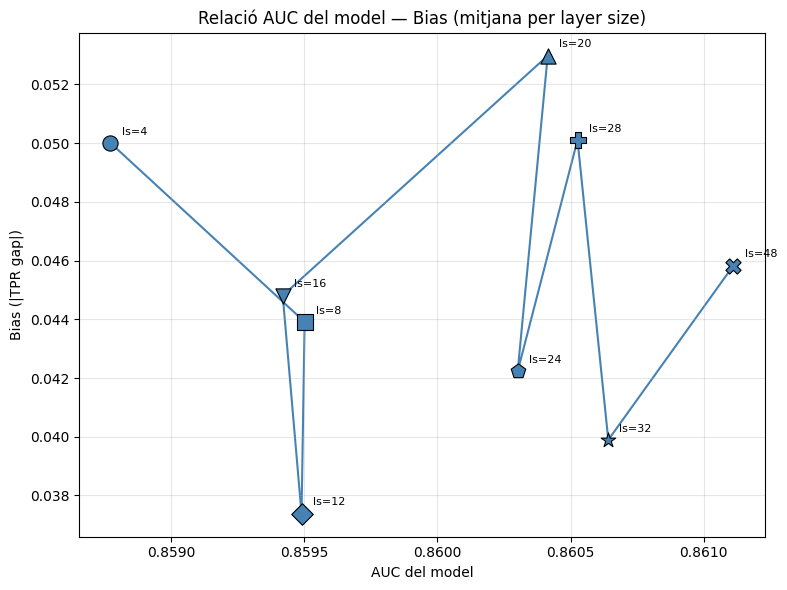

In [18]:
# ── Scatter: AUC del model vs Bias – mitjana per ls ─────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))

x_metric = 'auc_all'

sub = agg.dropna(subset=[f'{x_metric}_mean']).copy()
if SHOW_ALPHAS is not None:
    sub = sub[sub['alpha'].isin(SHOW_ALPHAS)]

# Mitjana per ls (agrupant tots els alphas)
grouped = sub.groupby('ls').agg(
    x_mean=(f'{x_metric}_mean', 'mean'),
    y_mean=('tpr_gap_mean', 'mean'),
).reset_index().sort_values('ls')

# Línia connectora
ax.plot(grouped['x_mean'], grouped['y_mean'],
        color='steelblue', linewidth=1.5, zorder=1)

# Marcadors per ls
for _, row in grouped.iterrows():
    ax.scatter(row['x_mean'], row['y_mean'],
               marker=ls_markers.get(int(row['ls']), 'x'),
               color='steelblue', s=120,
               edgecolor='black', linewidth=0.8, zorder=2)
    ax.annotate(f"ls={int(row['ls'])}", (row['x_mean'], row['y_mean']),
                textcoords='offset points', xytext=(8, 6), fontsize=8)

ax.set_xlabel('AUC del model')
ax.set_ylabel('Bias (|TPR gap|)')
ax.set_title('Relació AUC del model — Bias (mitjana per layer size)')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(EXP_DIR / 'scatter_model_auc_vs_bias_mean_per_ls.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

sub = agg.dropna(subset=['auc_all_mean', f'{sensitive_auc_col}_mean']).copy()

for _, row in sub.iterrows():
    a, l = row['alpha'], row['ls']
    ax.errorbar(
        row['auc_all_mean'], row[f'{sensitive_auc_col}_mean'],
        xerr=row['auc_all_std'], yerr=row[f'{sensitive_auc_col}_std'],
        fmt=ls_markers.get(l, 'x'),
        color=alpha_colors.get(a, 'gray'),
        markersize=9, capsize=3,
        markeredgecolor='black', markeredgewidth=0.5
    )

ax.axhline(0.5, color='green', linestyle='--', alpha=0.6,
           label=f'{sensitive_label} AUC = 0.5 (ideal)')

ax.set_xlabel('AUC del model')
ax.set_ylabel(f'{sensitive_label} AUC (ultima capa)')
ax.set_title(f'Relacio AUC del model - {sensitive_label} AUC')
ax.grid(True, alpha=0.3)

from matplotlib.lines import Line2D
legend_alpha = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
                       markersize=9, label=f'a={a}') for a, c in alpha_colors.items()]
legend_ls    = [Line2D([0],[0], marker=m, color='w', markerfacecolor='gray',
                       markersize=9, label=f'ls={l}') for l, m in ls_markers.items()]
leg1 = ax.legend(handles=legend_alpha, title='Alpha',
                 loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
ax.add_artist(leg1)
ax.legend(handles=legend_ls, title='Layer Size',
          loc='upper left', bbox_to_anchor=(1.02, 0.5), fontsize=8)

plt.tight_layout()
plt.savefig(EXP_DIR / f'scatter_auc_vs_{sensitive_auc_col}.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Boxplots: distribucio individual dels runs
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df_runs['config'] = df_runs.apply(lambda r: f"a={r['alpha']}\nls={r['ls']}", axis=1)
configs = (df_runs.sort_values(['alpha', 'ls'])
                  .drop_duplicates('config')['config'].tolist())

for ax, metric, title in [
    (axes[0], 'accuracy', 'Accuracy per configuracio'),
    (axes[1], 'tpr_gap',  'TPR gap per configuracio'),
]:
    data_per_config = [
        df_runs[df_runs['config'] == c][metric].dropna().tolist()
        for c in configs
    ]
    ax.boxplot(data_per_config, labels=configs, patch_artist=True)
    ax.set_xlabel('Configuracio (alpha, layer size)')
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.tick_params(axis='x', labelsize=6, rotation=45)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Distribucio dels {N_RUNS} runs per configuracio', fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / 'sweep_boxplots_v2.png', dpi=150, bbox_inches='tight')
plt.show()